<a href="https://colab.research.google.com/github/longdo9257/longdo9257.github.io/blob/main/Nov11_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# URL of the dataset
url = "https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/survival%2FLUNG_survival.txt"

# Load the tab-separated data into a pandas DataFrame
df = pd.read_csv(url, sep='\t')

# Display the first few rows of the DataFrame
df.head()

,sample,_PATIENT,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction
0,TCGA-05-4244-01,TCGA-05-4244,0,0.0,0.0,0.0,NaN,NaN,0,0.0,NaN
1,TCGA-05-4249-01,TCGA-05-4249,0,1523.0,0.0,1523.0,NaN,NaN,0,1523.0,NaN
2,TCGA-05-4250-01,TCGA-05-4250,1,121.0,NaN,121.0,NaN,NaN,0,121.0,NaN
3,TCGA-05-4382-01,TCGA-05-4382,0,607.0,0.0,607.0,1.0,334.0,1,334.0,NaN
4,TCGA-05-4384-01,TCGA-05-4384,0,426.0,0.0,426.0,NaN,NaN,1,183.0,NaN


In [2]:
survival_df = df
del df
survival_df.head()

,sample,_PATIENT,OS,OS.time,DSS,DSS.time,DFI,DFI.time,PFI,PFI.time,Redaction
0,TCGA-05-4244-01,TCGA-05-4244,0,0.0,0.0,0.0,NaN,NaN,0,0.0,NaN
1,TCGA-05-4249-01,TCGA-05-4249,0,1523.0,0.0,1523.0,NaN,NaN,0,1523.0,NaN
2,TCGA-05-4250-01,TCGA-05-4250,1,121.0,NaN,121.0,NaN,NaN,0,121.0,NaN
3,TCGA-05-4382-01,TCGA-05-4382,0,607.0,0.0,607.0,1.0,334.0,1,334.0,NaN
4,TCGA-05-4384-01,TCGA-05-4384,0,426.0,0.0,426.0,NaN,NaN,1,183.0,NaN


In [3]:
!pip install lifelines -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


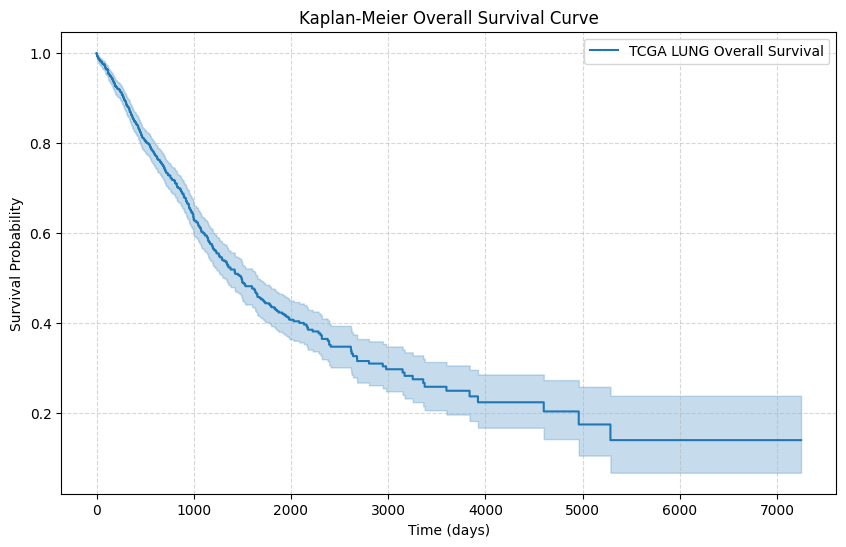

In [4]:
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# Drop rows where survival time or event indicator is missing
cleaned_df = survival_df.dropna(subset=['OS', 'OS.time'])

# Initialize the Kaplan-Meier fitter
kmf = KaplanMeierFitter()

# Fit the data
kmf.fit(durations=cleaned_df['OS.time'], event_observed=cleaned_df['OS'], label='TCGA LUNG Overall Survival')

# Plot the survival curve
plt.figure(figsize=(10, 6))
kmf.plot_survival_function()

plt.title('Kaplan-Meier Overall Survival Curve')
plt.xlabel('Time (days)')
plt.ylabel('Survival Probability')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()